In [ ]:
import pandas as pd

# Tumchya CSV file cha exact nav ithe dya
df = pd.read_csv(r"C:\Users\khond\Downloads\online-retail-dataset.csv")

# Data che pahile 5 rows baghnyasathi
print(df.head())



  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non

##Step 2 Data Cleaning

In [3]:
# 1. Kontya column madhe kiti missing values ahet te check karne
print("Missing values in each column:")
print(df.isnull().sum())

# 2. Duplicate rows remove karne
df = df.drop_duplicates()

# 3. CustomerID madhlya missing values la drop kinva fill karu shakta (sadhya drop karuya)
df = df.dropna(subset=['CustomerID'])

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


##Step: Missing Values Handling and Data Cleaning

In [4]:
# 1. Missing CustomerID remove karne
df = df.dropna(subset=['CustomerID'])

# 2. Description madhlya missing values la 'Unknown' ne fill karne
df['Description'] = df['Description'].fillna('Unknown')

# 3. Negative quantity ya unit price asel (returns/cancellations) tar tyanna check karu shakta
# Sadhya fakt positive values filter karuya (jar sales analysis karaycha asel)
df = df[df['Quantity'] > 0]
df = df[df['UnitPrice'] > 0]

# 4. Cleaned rows kiti urlyat te check karne
print("Total rows after cleaning:", df.shape[0])

Total rows after cleaning: 392692


In [5]:
# 1. Total Sales column banavne (Quantity * UnitPrice)
df['TotalSales'] = df['Quantity'] * df['UnitPrice']

# 2. InvoiceDate la datetime format madhe convert karne
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# 3. Check karnyasathi pahile 5 rows print karne
print(df[['InvoiceNo', 'Quantity', 'UnitPrice', 'TotalSales', 'InvoiceDate']].head())

  InvoiceNo  Quantity  UnitPrice  TotalSales         InvoiceDate
0    536365         6       2.55       15.30 2010-12-01 08:26:00
1    536365         6       3.39       20.34 2010-12-01 08:26:00
2    536365         8       2.75       22.00 2010-12-01 08:26:00
3    536365         6       3.39       20.34 2010-12-01 08:26:00
4    536365         6       3.39       20.34 2010-12-01 08:26:00


##Step: Feature Engineering (Total Sales & Date Formatting)

In [6]:
# 1. Total Sales column banavne
df['TotalSales'] = df['Quantity'] * df['UnitPrice']

# 2. InvoiceDate la datetime format madhe convert karne
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# 3. Date madhun Year ani Month separate karne (Future analysis sathi)
df['Year'] = df['InvoiceDate'].dt.year
df['Month'] = df['InvoiceDate'].dt.month

# 4. Pahile 5 rows check karne
print(df[['InvoiceNo', 'Quantity', 'UnitPrice', 'TotalSales', 'InvoiceDate']].head())

  InvoiceNo  Quantity  UnitPrice  TotalSales         InvoiceDate
0    536365         6       2.55       15.30 2010-12-01 08:26:00
1    536365         6       3.39       20.34 2010-12-01 08:26:00
2    536365         8       2.75       22.00 2010-12-01 08:26:00
3    536365         6       3.39       20.34 2010-12-01 08:26:00
4    536365         6       3.39       20.34 2010-12-01 08:26:00


##Step 1: Top 5 Best Selling Products Shodhne

In [7]:
# Highest sales denare top 5 products
top_products = df.groupby('Description')['TotalSales'].sum().sort_values(ascending=False).head(5)
print("--- Top 5 Products by Revenue ---")
print(top_products)

--- Top 5 Products by Revenue ---
Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
Name: TotalSales, dtype: float64


##Step 2: Monthly Sales Trend Check Karne

In [8]:
# Mahinyanusal sales kashi zali te baghne
monthly_sales = df.groupby(['Year', 'Month'])['TotalSales'].sum()
print("\n--- Monthly Revenue ---")
print(monthly_sales)


--- Monthly Revenue ---
Year  Month
2010  12        570422.730
2011  1         568101.310
      2         446084.920
      3         594081.760
      4         468374.331
      5         677355.150
      6         660046.050
      7         598962.901
      8         644051.040
      9         950690.202
      10       1035642.450
      11       1156205.610
      12        517190.440
Name: TotalSales, dtype: float64


##Step 3: Top 5 Countries (Revenue wise)

In [9]:
# Kuthlya deshatun sarvat jast revenue ala
top_countries = df.groupby('Country')['TotalSales'].sum().sort_values(ascending=False).head(5)
print("\n--- Top 5 Countries by Revenue ---")
print(top_countries)


--- Top 5 Countries by Revenue ---
Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Name: TotalSales, dtype: float64


##Step 4: Clean Data Save Karne

In [10]:
# Cleaned dataset save karne
df.to_csv('cleaned_ecommerce_data.csv', index=False)
print("\nCleaned dataset saved as 'cleaned_ecommerce_data.csv' successfully!")


Cleaned dataset saved as 'cleaned_ecommerce_data.csv' successfully!


##insights che charts ani graphs

C:\Users\khond\AppData\Local\Temp\ipykernel_24308\2564392289.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_products.values, y=top_products.index, palette='Blues_r')


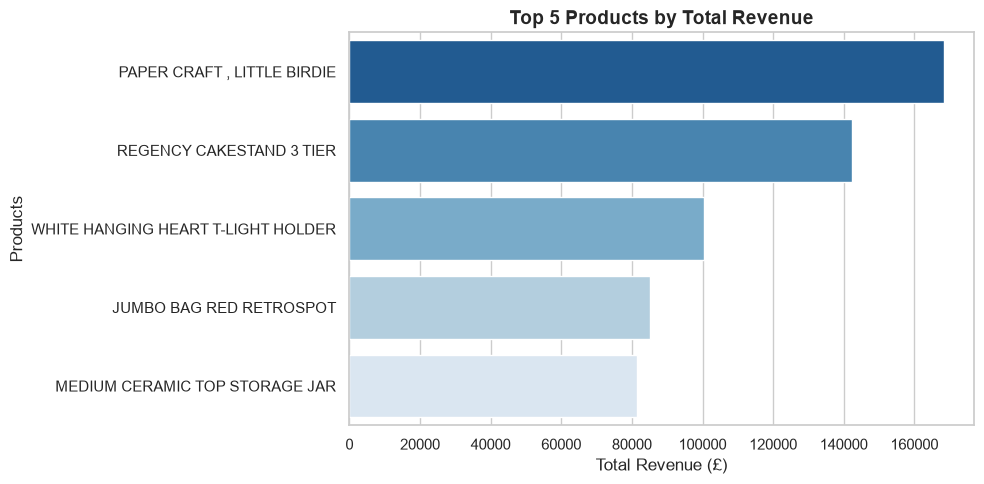

C:\Users\khond\AppData\Local\Temp\ipykernel_24308\2564392289.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.index, y=top_countries.values, palette='viridis')


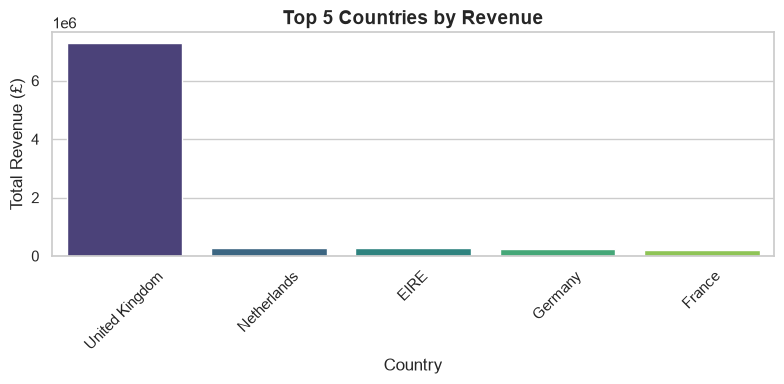

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Style set karne
sns.set_theme(style="whitegrid")

# 1. Top 5 Products by Revenue (Bar Chart)
plt.figure(figsize=(10, 5))
top_products = df.groupby('Description')['TotalSales'].sum().sort_values(ascending=False).head(5)
sns.barplot(x=top_products.values, y=top_products.index, palette='Blues_r')
plt.title('Top 5 Products by Total Revenue', fontsize=14, fontweight='bold')
plt.xlabel('Total Revenue (£)', fontsize=12)
plt.ylabel('Products', fontsize=12)
plt.tight_layout()
plt.show()

# 2. Top 5 Countries by Revenue (Bar Chart)
plt.figure(figsize=(8, 4))
top_countries = df.groupby('Country')['TotalSales'].sum().sort_values(ascending=False).head(5)
sns.barplot(x=top_countries.index, y=top_countries.values, palette='viridis')
plt.title('Top 5 Countries by Revenue', fontsize=14, fontweight='bold')
plt.xlabel('Country', fontsize=12)
plt.ylabel('Total Revenue (£)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()